## A/B Testing Analysis | E-Commerce Conversion Rates

### Project Overview

This project analyzes the results of an A/B test to determine whether a new webpage leads to higher conversion rates than an existing webpage.

Using Python, I examine customer conversion behavior across control and treatment groups, explore differences by country, and apply statistical hypothesis testing to evaluate whether the observed improvement is statistically significant.

The analysis includes descriptive statistics, probability calculations, simulation-based hypothesis testing, and logistic regression.

### Business Objective: 
Determine whether the company has sufficient statistical evidence to adopt the new webpage based on its impact on customer conversions.


In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
%matplotlib inline
#We are setting the seed to assure you get the same answers on quizzes as we set up
random.seed(0)

In [2]:
df = pd.read_csv('ab_data.csv')
df.head()

,country,group,converted
0,UK,control,0
1,US,treatment,1
2,UK,treatment,0
3,UK,control,0
4,UK,treatment,0


In [3]:
df.shape

(69889, 3)

In [4]:
df['converted'].sum()/len(df)

0.13047832992316388

In [5]:
df.isnull().values.any()

False

In [6]:
# number of visitors from each country
Country_counts= df['country'].value_counts()
Country_counts


US    48850
UK    17551
CA     3488
Name: country, dtype: int64

# How many visitors?

In [7]:
df['group'].value_counts()

treatment    35211
control      34678
Name: group, dtype: int64

$

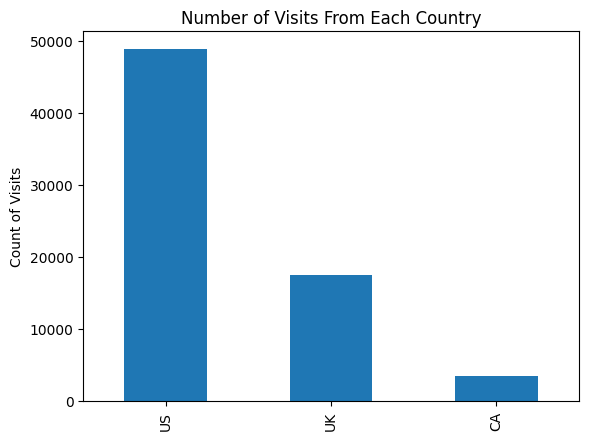

In [8]:
# bar chart of results
df['country'].value_counts().plot(kind='bar');
plt.title('Number of Visits From Each Country');
plt.ylabel('Count of Visits');
plt.show();

In [9]:
df.dtypes

country      object
group        object
converted     int64
dtype: object

### The 'converted' column is not categorical.

`g)` What are the possible values of the `converted` column?  Does it make sense that these values are the only possible values? Why or why not? 



In [10]:
df['converted'].value_counts()

0    60770
1     9119
Name: converted, dtype: int64

#### What is the probability of an individual converting regardless of the page they receive or the country they are from? Simply, what is the chance of conversion in the dataset?

In [11]:
df['converted'].mean()

0.13047832992316388

#### Given that an individual was in the `control` group, what is the probability they converted?

In [12]:
df.query('group == "control"')['converted'].mean()

0.1052540515600669

#### Given that an individual was in the `treatment` group, what is the probability they converted?

In [13]:
df.query('group == "treatment"')['converted'].mean()

0.15532078043793132

### Compared to the conversion rate of the control group ( which is 0.105..), the conversion rate of the treatment group is slightly higher at the rate of 0.155..

In [14]:
(df['group'] == 'treatment').mean()

0.5038131894861853

In [15]:
(df['country'] == 'CA').mean()

0.04990771079855199

#### Given that an individual was in the `US`, what was the probability that they `converted`? 



In [16]:
df.query('country == "US"')['converted'].mean()

0.13277379733879222

#### Given that an individual was in the `UK`, what was the probability that they `converted`? 

In [17]:
df.query('country == "UK"')['converted'].mean()

0.12512107572218106

### The evidence shows that the conversion rate is higher in the UK compared to the US.

In [18]:
# Method 1  - explicitly calculate each probability
print(df.query('country == "US" and group == "control" and converted == 1').shape[0]/df.query('country == "US" and group == "control"').shape[0]) 
print(df.query('country == "US" and group == "treatment" and converted == 1').shape[0]/df.query('country == "US" and group == "treatment"').shape[0])

0.10731404958677686
0.1577687626774848


In [19]:
print(df.query('country == "UK" and group == "control" and converted == 1').shape[0]/df.query('country == "UK" and group == "control"').shape[0]) 
print(df.query('country == "UK" and group == "treatment" and converted == 1').shape[0]/df.query('country == "UK" and group == "treatment"').shape[0])

0.10164866401364411
0.148698035632709


In [20]:
print(df.query('country == "CA" and group == "control" and converted == 1').shape[0]/df.query('country == "CA" and group == "control"').shape[0]) 
print(df.query('country == "CA" and group == "treatment" and converted == 1').shape[0]/df.query('country == "CA" and group == "treatment"').shape[0])

0.0944741532976827
0.15401662049861495


In [21]:
# Method 2 - quickly calculate using `groupby`
df.query('country == "US"').groupby('group')['converted'].mean()

group
control      0.107314
treatment    0.157769
Name: converted, dtype: float64

In [22]:
df.query('country == "UK"').groupby('group')['converted'].mean()

group
control      0.101649
treatment    0.148698
Name: converted, dtype: float64

<a id='experimentation'></a>

### Experimentation

This section uses hypothesis testing to determine whether the treatment page has a higher conversion rate than the control page, at a **5% significance level**.

- **H₀:** The treatment page performs equally or worse.
- **H₁:** The treatment page performs better.

$H_0: p_{treatment} - p_{control} \leq 0$

$H_1: p_{treatment} - p_{control} > 0$

Where $p_{control}$ and $p_{treatment}$ represent their respective conversion rates.

Country differences are not considered in this analysis.

In [23]:
p_control_treatment_null  = df['converted'].mean()
n_treatment = df.query('group == "treatment"').shape[0]
n_control = df.query('group == "control"').shape[0]


In [24]:
p_treatment_null = df['converted'].mean()
treatment_converted = np.random.binomial(1, p_treatment_null, n_treatment)
treatment_converted

array([0, 0, 0, ..., 0, 0, 0])

In [25]:
p_control_null = df['converted'].mean()
control_converted = np.random.binomial(1, p_control_null, n_control)
control_converted

array([0, 0, 0, ..., 0, 0, 0])

In [26]:
treatment_converted.mean() - control_converted.mean()

0.0009089256574745519

In [27]:
treatment_converted.mean()

0.13035699071312942

In [28]:
p_diffs = []
for _ in range(500):
    #calculate p_treatment and p_control under the null
    p_treatment_null = df['converted'].mean()
    p_control_null   = df['converted'].mean()

    #simulate the treatment and control converted arrays
    treatment_converted = np.random.binomial(1, p_treatment_null, n_treatment)
    control_converted = np.random.binomial(1, p_control_null, n_control)

    #calculate the difference between p_treatment_null and p_control_null
    p_diff = treatment_converted.mean() - control_converted.mean()
     #add p_diff to the p_diffs array
    p_diffs.append(p_diff)

<AxesSubplot: >

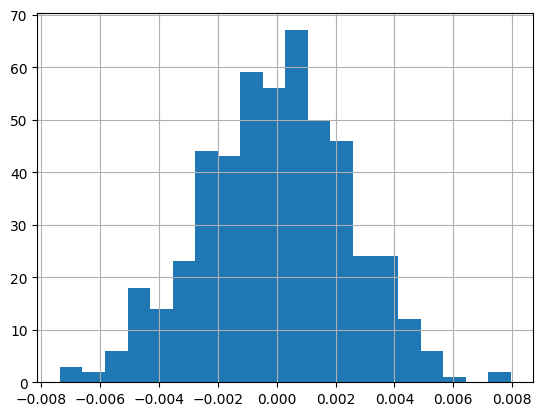

In [29]:
p_diffs = pd.Series(p_diffs)
p_diffs.hist(bins=20)


#### What proportion of the **p_diffs** are greater than the difference observed between `treatment` and `control` in `df`?

In [30]:
p_treatment = df.query('group == "treatment"')['converted'].mean()
p_control   = df.query('group == "control"')['converted'].mean()

In [31]:
p_treatment.mean()

0.15532078043793132

In [32]:
p_control.mean()

0.1052540515600669

In [33]:
obs_diff = p_treatment - p_control

In [34]:
(p_diffs > obs_diff).mean()

0.0

In [35]:
p_diff.mean()

0.00036192790204486736

### 0.0 proportion of the p_diffs are greater than the differences observed between treatment and control in df.

### The P-value is 0.0. The p-value represents the probability of observing a difference in conversion rates as large as or larger than the one observed, assuming that there is no true difference between the new and old pages. In this case, the p-value is 0.0, which is less than the Type I error rate of 0.05. Therefore, we reject the null hypothesis and conclude that there is statistically significant difference between the new and old pages.**

### Logistic Regression
**While hypothesis testing evaluates whether the treatment page outperforms the control page, logistic regression examines the relationship between webpage type and conversion, including whether that relationship changes after accounting for country.

In [36]:
df['intercept'] = 1
df['ab_page'] = pd.get_dummies(df['group'])['treatment']
df.head()

,country,group,converted,intercept,ab_page
0,UK,control,0,1,0
1,US,treatment,1,1,1
2,UK,treatment,0,1,1
3,UK,control,0,1,0
4,UK,treatment,0,1,1


In [37]:
X = df[['intercept', 'ab_page']]
y = df['converted']

In [38]:
import statsmodels.api as sm

# Logit Model
logit_mod = sm.Logit(y, X)
logit_res = logit_mod.fit()

Optimization terminated successfully.
         Current function value: 0.384516
         Iterations 6


In [39]:
print(logit_res.summary())

                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:                69889
Model:                          Logit   Df Residuals:                    69887
Method:                           MLE   Df Model:                            1
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                0.007175
Time:                        03:45:39   Log-Likelihood:                -26873.
converged:                       True   LL-Null:                       -27068.
Covariance Type:            nonrobust   LLR p-value:                 1.810e-86
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -2.1402      0.017   -122.305      0.000      -2.174      -2.106
ab_page        0.4467      0.023     19.539      0.000       0.402       0.492


### The logistic regression results are consistent with the earlier hypothesis test. The p-value for `ab_page` is less than 0.001, indicating a statistically significant relationship between webpage type and conversion. The positive coefficient suggests that users receiving the treatment page have higher odds of converting than those receiving the control page.

In [40]:
### Create the necessary dummy variables
df[['CA', 'UK', 'US']] = pd.get_dummies(df['country'])
df = df.drop('CA', axis=1)
df.head()

,country,group,converted,intercept,ab_page,UK,US
0,UK,control,0,1,0,1,0
1,US,treatment,1,1,1,0,1
2,UK,treatment,0,1,1,1,0
3,UK,control,0,1,0,1,0
4,UK,treatment,0,1,1,1,0


In [41]:
X = df[['intercept', 'ab_page', 'US', 'UK']]
y = y = df['converted']

In [42]:
model = sm.Logit(y, X)
results = model.fit()

Optimization terminated successfully.
         Current function value: 0.384463
         Iterations 6


In [43]:
print(results.summary())

                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:                69889
Model:                          Logit   Df Residuals:                    69885
Method:                           MLE   Df Model:                            3
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                0.007312
Time:                        03:45:42   Log-Likelihood:                -26870.
converged:                       True   LL-Null:                       -27068.
Covariance Type:            nonrobust   LLR p-value:                 1.778e-85
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -2.1930      0.053    -41.308      0.000      -2.297      -2.089
ab_page        0.4466      0.023     19.534      0.000       0.402       0.491
US             0.0727      0.053      1.372      0.1

**The p-values associated with the US and UK variables are greater than 0.05, suggesting that there is no statistically significant difference in conversion rates between users in the US or UK compared to the baseline group (CA).**